# 02 · Naive Bayes Gaussiano

Formulación: ŷ = argmax_k log P(y=k) + Σ_j log 𝒩(x_j; μ_kj, σ²_kj). Solución cerrada por máxima verosimilitud. Se entrena, se busca `var_smoothing`, se evalúa con las métricas de clasificación y calibración, y se verifica la implementación en NumPy contra `GaussianNB`.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from familia3 import SEED
np.random.seed(SEED)
%matplotlib inline


In [2]:
from familia3 import datos as D
from familia3.pipelines import pipeline_naive_bayes
from familia3.busqueda import buscar_naive_bayes
from familia3.metricas import metricas_clasificacion
from familia3 import graficos as G

cancer = D.cargar_breast_cancer()


## Entrenamiento base y búsqueda de `var_smoothing`

In [3]:
modelo_base = pipeline_naive_bayes().fit(cancer.X_train, cancer.y_train)
busqueda = buscar_naive_bayes(cancer.X_train, cancer.y_train)
print("mejor var_smoothing:", busqueda.best_params_, "roc_auc (cv):", round(busqueda.best_score_, 4))
modelo = busqueda.best_estimator_


mejor var_smoothing: {'clf__var_smoothing': np.float64(1e-12)} roc_auc (cv): 0.9884


## Métricas sobre el conjunto de prueba (tocado una sola vez)

In [4]:
y_pred = modelo.predict(cancer.X_test)
y_proba = modelo.predict_proba(cancer.X_test)
m = metricas_clasificacion(cancer.y_test, y_pred, y_proba)
for k, v in m.items():
    print(f"{k:12s}: {v:.4f}")


precision   : 0.9444
recall      : 0.9444
f1          : 0.9444
roc_auc     : 0.9868
log_loss    : 0.4394
brier       : 0.0609


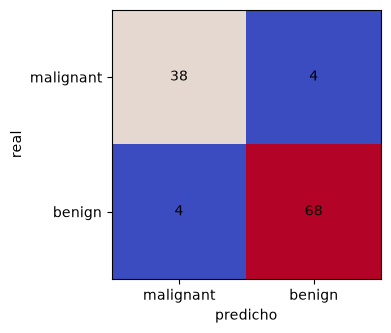

In [5]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(cancer.y_test, y_pred)
fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(cm, cmap="coolwarm")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(cancer.nombres_clases); ax.set_yticklabels(cancer.nombres_clases)
ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.savefig("../reports/figuras/02_matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()


## Gráficos: frontera 2D, curva de calibración, curva de aprendizaje

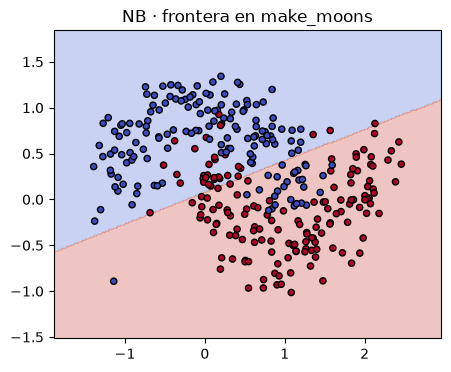

In [6]:
moons = D.sintetico_moons()
modelo_moons = pipeline_naive_bayes().fit(moons.X_train, moons.y_train)
G.frontera_decision(modelo_moons, moons.X_train, moons.y_train, "02_nb_frontera_moons.png", "NB · frontera en make_moons")
plt.show()


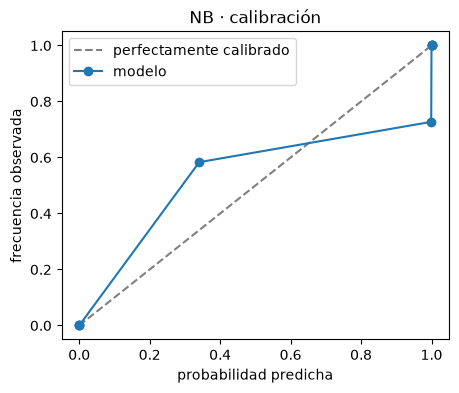

In [7]:
G.curva_calibracion_manual(cancer.y_test, y_proba[:, 1], "02_nb_calibracion.png", "NB · calibración")
plt.show()


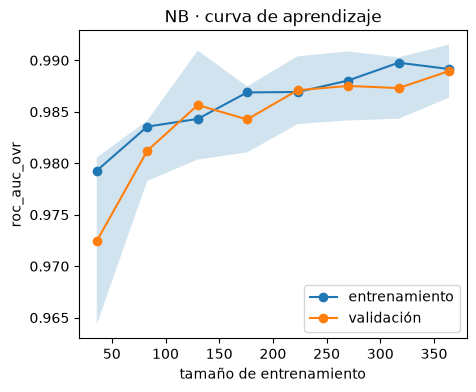

In [8]:
G.curva_aprendizaje(modelo, cancer.X_train, cancer.y_train, "02_nb_aprendizaje.png", "NB · curva de aprendizaje")
plt.show()


## Importancia por permutación (NB no trae importancia propia)

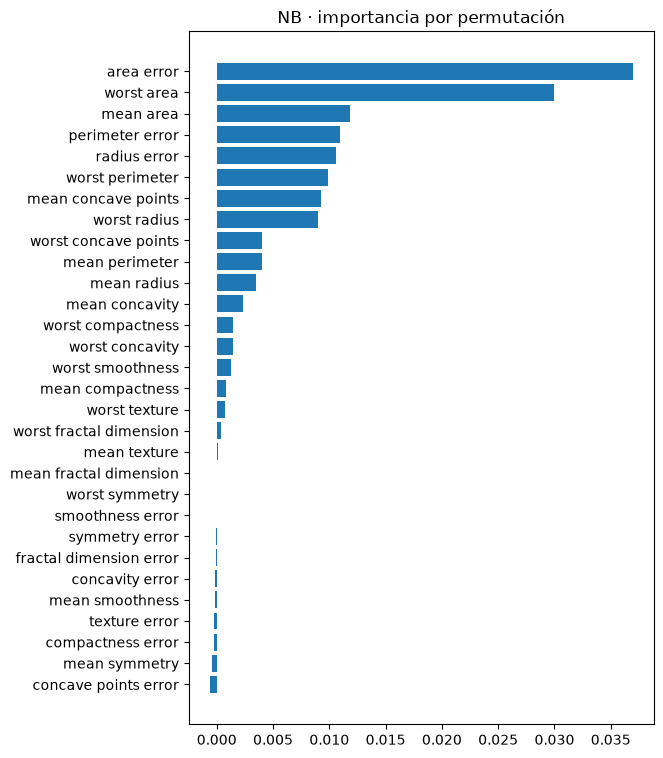

In [9]:
from sklearn.inspection import permutation_importance
resultado = permutation_importance(modelo, cancer.X_test, cancer.y_test, n_repeats=20, random_state=SEED, scoring="roc_auc")
G.importancia_permutacion(resultado.importances_mean, cancer.nombres_atributos, "02_nb_importancia.png", "NB · importancia por permutación")
plt.show()


## Experimento de supuestos: ¿qué pasa si aumentamos la correlación entre atributos?

correlación inducida=0.0 -> roc_auc=0.9590
correlación inducida=0.3 -> roc_auc=0.9464
correlación inducida=0.6 -> roc_auc=0.7110
correlación inducida=0.9 -> roc_auc=0.5129


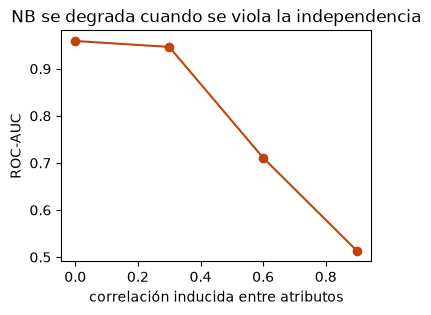

In [10]:
from familia3.pipelines import pipeline_naive_bayes as pnb

rng = np.random.default_rng(SEED)
resultados = []
for nivel_correlacion in [0.0, 0.3, 0.6, 0.9]:
    ruido_compartido = rng.normal(size=(len(cancer.X_train), 1))
    X_sintetico = cancer.X_train[:, :5].copy()
    X_sintetico = (1 - nivel_correlacion) * X_sintetico + nivel_correlacion * ruido_compartido * X_sintetico.std(axis=0)
    m = pnb().fit(X_sintetico, cancer.y_train)
    X_test_sint = (1 - nivel_correlacion) * cancer.X_test[:, :5] + nivel_correlacion * rng.normal(size=(len(cancer.X_test), 1)) * cancer.X_test[:, :5].std(axis=0)
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(cancer.y_test, m.predict_proba(X_test_sint)[:, 1])
    resultados.append((nivel_correlacion, auc))
    print(f"correlación inducida={nivel_correlacion:.1f} -> roc_auc={auc:.4f}")

fig, ax = plt.subplots(figsize=(4, 3))
niveles, aucs = zip(*resultados)
ax.plot(niveles, aucs, "o-", color="#c1440e")
ax.set_xlabel("correlación inducida entre atributos")
ax.set_ylabel("ROC-AUC")
ax.set_title("NB se degrada cuando se viola la independencia")
plt.savefig("../reports/figuras/02_nb_degradacion_correlacion.png", dpi=150, bbox_inches="tight")
plt.show()


## Verificación matemática: NumPy vs `GaussianNB`

In [11]:
from familia3.desde_cero import NaiveBayesGaussianoNumPy
from sklearn.naive_bayes import GaussianNB

propio = NaiveBayesGaussianoNumPy().fit(cancer.X_train, cancer.y_train)
referencia = GaussianNB().fit(cancer.X_train, cancer.y_train)
diferencia = np.max(np.abs(propio.predict_proba(cancer.X_test) - referencia.predict_proba(cancer.X_test)))
print("diferencia máxima NumPy vs sklearn:", diferencia)
assert diferencia < 1e-10
print("Verificado: coincide con GaussianNB dentro de 1e-10.")


diferencia máxima NumPy vs sklearn: 0.0
Verificado: coincide con GaussianNB dentro de 1e-10.
